# Module 3 Assignment: MNIST Classification

Now that we have the full power of PyTorch at our disposal, we would like to classify a more concrete dataset. In particular, we are going to look at building a classifier for the [MNIST Handwritten Digits dataset](https://en.wikipedia.org/wiki/MNIST_database). This dataset contains tens of thousands of handwritten digits from 0-9 and is very commonly used for machine learning algorithm development. In this assignment, we will provide some basic dataloading code and would like you to build a deep neural network that is trained on the MNIST dataset! Feel free to reuse code you have written or seen before in previous notebooks!

In [2]:
import torch
import torch.nn as nn
import torchvision.datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data.sampler import SubsetRandomSampler
import time, copy

# device config (train our model on GPU if it is available which is much faster)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

First we will load in our MNIST dataset. Pytorch provides built in functions for loading popular image datasets, MNIST is one of them.

In [3]:
# These transforms will be performed on every datapoint - in this example we want to transform every
# datapoint to a Tensor datatype, and perform
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
mnist_train = torchvision.datasets.MNIST('', train=True, transform =transform, download=True)
# We will split out train dataset into train and validation!
mnist_train, mnist_val = torch.utils.data.random_split(mnist_train, [50000, 10000])
mnist_test = torchvision.datasets.MNIST('', train=False, transform = transform, download=True)


100%|██████████| 9.91M/9.91M [00:00<00:00, 65.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.3MB/s]


In [4]:
# We will create DataLoaders just like before with a batch size of 100
batch_size = 100
dataloaders = {'train': DataLoader(mnist_train, batch_size=batch_size),
               'val': DataLoader(mnist_val, batch_size=batch_size),
               'test': DataLoader(mnist_test, batch_size=batch_size)}

dataset_sizes = {'train': len(mnist_train),
                 'val': len(mnist_val),
                 'test': len(mnist_test)}
print(f'dataset_sizes = {dataset_sizes}')

dataset_sizes = {'train': 50000, 'val': 10000, 'test': 10000}


In [5]:
# Hint! In the Module 3 Introduction to Pytorch notebook, the Network
# we created required the input data to be of shape Nx1 where N is the number of
# features. Currently, our MNIST dataset is shape 28x28 as they are images. Use
# this code snippet as you iterate through the datapoint in your dataset to flatten
# them so it is size 784x1 and can be used with the models we designed previously!

# This loop only iterates through the "train" datapoints
# In the previous notebook
phases = ["train", "val", "test"]
for phase in phases:
  for inputs, labels in dataloaders[phase]:
    # This flattens every every batch to the correct size!
    inputs = inputs.view(inputs.shape[0],-1)

In [6]:
# Your code here!
import matplotlib.pyplot as plt
import sklearn.metrics as metrics

class MNISTClassifier(nn.Module):
    def __init__(self, input_size=784, hidden1=256, hidden2=128, num_classes=10, dropout=0.2): #28 by 28 = 784, hence the input size of 784
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, hidden1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),    nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden2, num_classes)  # raw logits
        )

    def forward(self, x):
        return self.layers(x)

model = MNISTClassifier().to(device)


# --- Training loop ---
def train_model(model, dataloaders, dataset_sizes, criterion, optimizer, scheduler, num_epochs=15):
    start = time.time()
    best_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    curves = {f'{p}_{m}': [] for p in ['train', 'val', 'test'] for m in ['loss', 'acc']}

    for epoch in range(num_epochs):
        for phase in ['train', 'val', 'test']:
            model.train() if phase == 'train' else model.eval()  # toggles dropout
            running_loss, running_correct = 0.0, 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.view(inputs.shape[0], -1).to(device)  # flatten to Nx784
                labels = labels.to(device)

                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):  # grads only when training
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    preds = outputs.argmax(dim=1)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_correct += (preds == labels).sum().item()

            if phase == 'train':
                scheduler.step()  # decay LR once per epoch

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_correct / dataset_sizes[phase]
            curves[f'{phase}_loss'].append(epoch_loss)
            curves[f'{phase}_acc'].append(epoch_acc)

            # keep the weights with the best *validation* accuracy
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_wts = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1:2d}/{num_epochs} | "
              f"train acc {curves['train_acc'][-1]:.4f} | "
              f"val acc {curves['val_acc'][-1]:.4f} | "
              f"test acc {curves['test_acc'][-1]:.4f}")

    print(f"Done in {time.time()-start:.0f}s. Best val acc: {best_acc:.4f}")
    model.load_state_dict(best_wts)
    return model, curves

In [7]:
# Utility functions for plotting your results!
def plot_training_curves(training_curves,
                         phases=['train', 'val', 'test'],
                         metrics=['loss','acc']):
    epochs = list(range(len(training_curves['train_loss'])))
    for metric in metrics:
        plt.figure()
        plt.title(f'Training curves - {metric}')
        for phase in phases:
            key = phase+'_'+metric
            if key in training_curves:
                plt.plot(epochs, training_curves[phase+'_'+metric])
        plt.xlabel('epoch')
        plt.legend(labels=phases)

def classify_predictions(model, device, dataloader):
    model.eval()   # Set model to evaluate mode
    all_labels = torch.tensor([]).to(device)
    all_scores = torch.tensor([]).to(device)
    all_preds = torch.tensor([]).to(device)
    for inputs, labels in dataloader:
        # Important! We need to flatten every datapoint
        inputs = inputs.view(inputs.shape[0], -1)
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = torch.softmax(model(inputs),dim=1)
        _, preds = torch.max(outputs, 1)
        scores = outputs[:,1]
        all_labels = torch.cat((all_labels, labels), 0)
        all_scores = torch.cat((all_scores, scores), 0)
        all_preds = torch.cat((all_preds, preds), 0)
    return all_preds.detach().cpu(), all_labels.detach().cpu(), all_scores.detach().cpu()

def plot_cm(model, device, dataloaders, phase='test'):
    class_labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    preds, labels, scores = classify_predictions(model, device, dataloaders[phase])

    cm = metrics.confusion_matrix(labels, preds)
    disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    ax = disp.plot().ax_
    ax.set_title('Confusion Matrix -- counts')


In [10]:
num_epochs = 15
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

model, training_curves = train_model(model, dataloaders, dataset_sizes,
                                     criterion, optimizer, scheduler, num_epochs=num_epochs)

Epoch  1/15 | train acc 0.8579 | val acc 0.9346 | test acc 0.9399
Epoch  2/15 | train acc 0.9338 | val acc 0.9502 | test acc 0.9500
Epoch  3/15 | train acc 0.9495 | val acc 0.9646 | test acc 0.9644
Epoch  4/15 | train acc 0.9566 | val acc 0.9690 | test acc 0.9668
Epoch  5/15 | train acc 0.9633 | val acc 0.9677 | test acc 0.9678
Epoch  6/15 | train acc 0.9672 | val acc 0.9725 | test acc 0.9715
Epoch  7/15 | train acc 0.9703 | val acc 0.9730 | test acc 0.9739
Epoch  8/15 | train acc 0.9732 | val acc 0.9753 | test acc 0.9742
Epoch  9/15 | train acc 0.9752 | val acc 0.9768 | test acc 0.9758
Epoch 10/15 | train acc 0.9779 | val acc 0.9771 | test acc 0.9767
Epoch 11/15 | train acc 0.9794 | val acc 0.9785 | test acc 0.9766
Epoch 12/15 | train acc 0.9808 | val acc 0.9783 | test acc 0.9790
Epoch 13/15 | train acc 0.9818 | val acc 0.9778 | test acc 0.9778
Epoch 14/15 | train acc 0.9832 | val acc 0.9796 | test acc 0.9784
Epoch 15/15 | train acc 0.9835 | val acc 0.9789 | test acc 0.9792
Done in 22

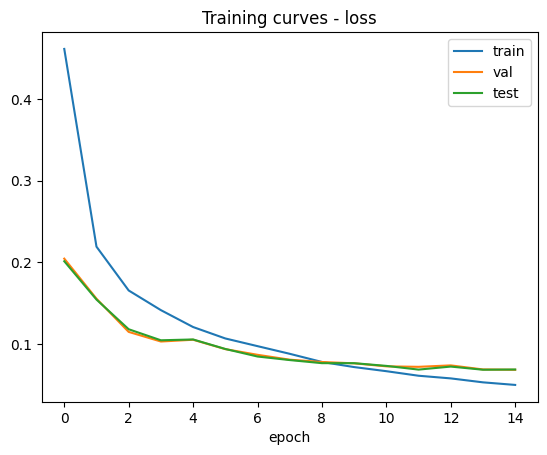

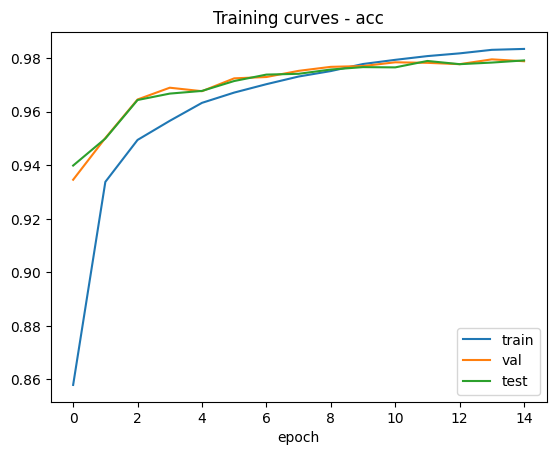

In [11]:
plot_training_curves(training_curves, phases=['train', 'val', 'test'])

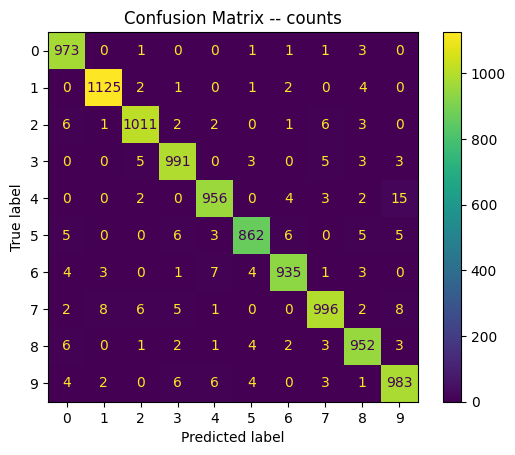

In [12]:
res = plot_cm(model, device, dataloaders, phase='test')

## Results and Interpretation

I trained a fully connected network (784 → 256 → 128 → 10, ReLU, dropout 0.2) on flattened MNIST
images for 15 epochs, using cross-entropy loss, Adam (lr = 1e-3, weight decay 1e-5), and an
exponential learning-rate decay (γ = 0.9). The weights with the best validation accuracy were kept.

**Performance.** The final test accuracy was about 97.92%, close to the validation accuracy of
97.89%. The loss curves fall steadily, and the train/val/test curves stay close together, so the
model generalizes well and is not badly overfitting.

**Confusion matrix.** Most predictions lie on the diagonal. The most common mistakes were
4↔9 and 7↔2, which are digits that look somewhat alike when handwritten.

**Possible improvements.** A convolutional network would likely push accuracy above 97.9%, since it
uses the 2D structure of the images that flattening discards. More epochs or tuning the
learning rate and dropout could also help slightly or moderately.